<a href="https://colab.research.google.com/github/EstherWare/-plp-da-a4-student-eda-and-board-report/blob/main/board_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

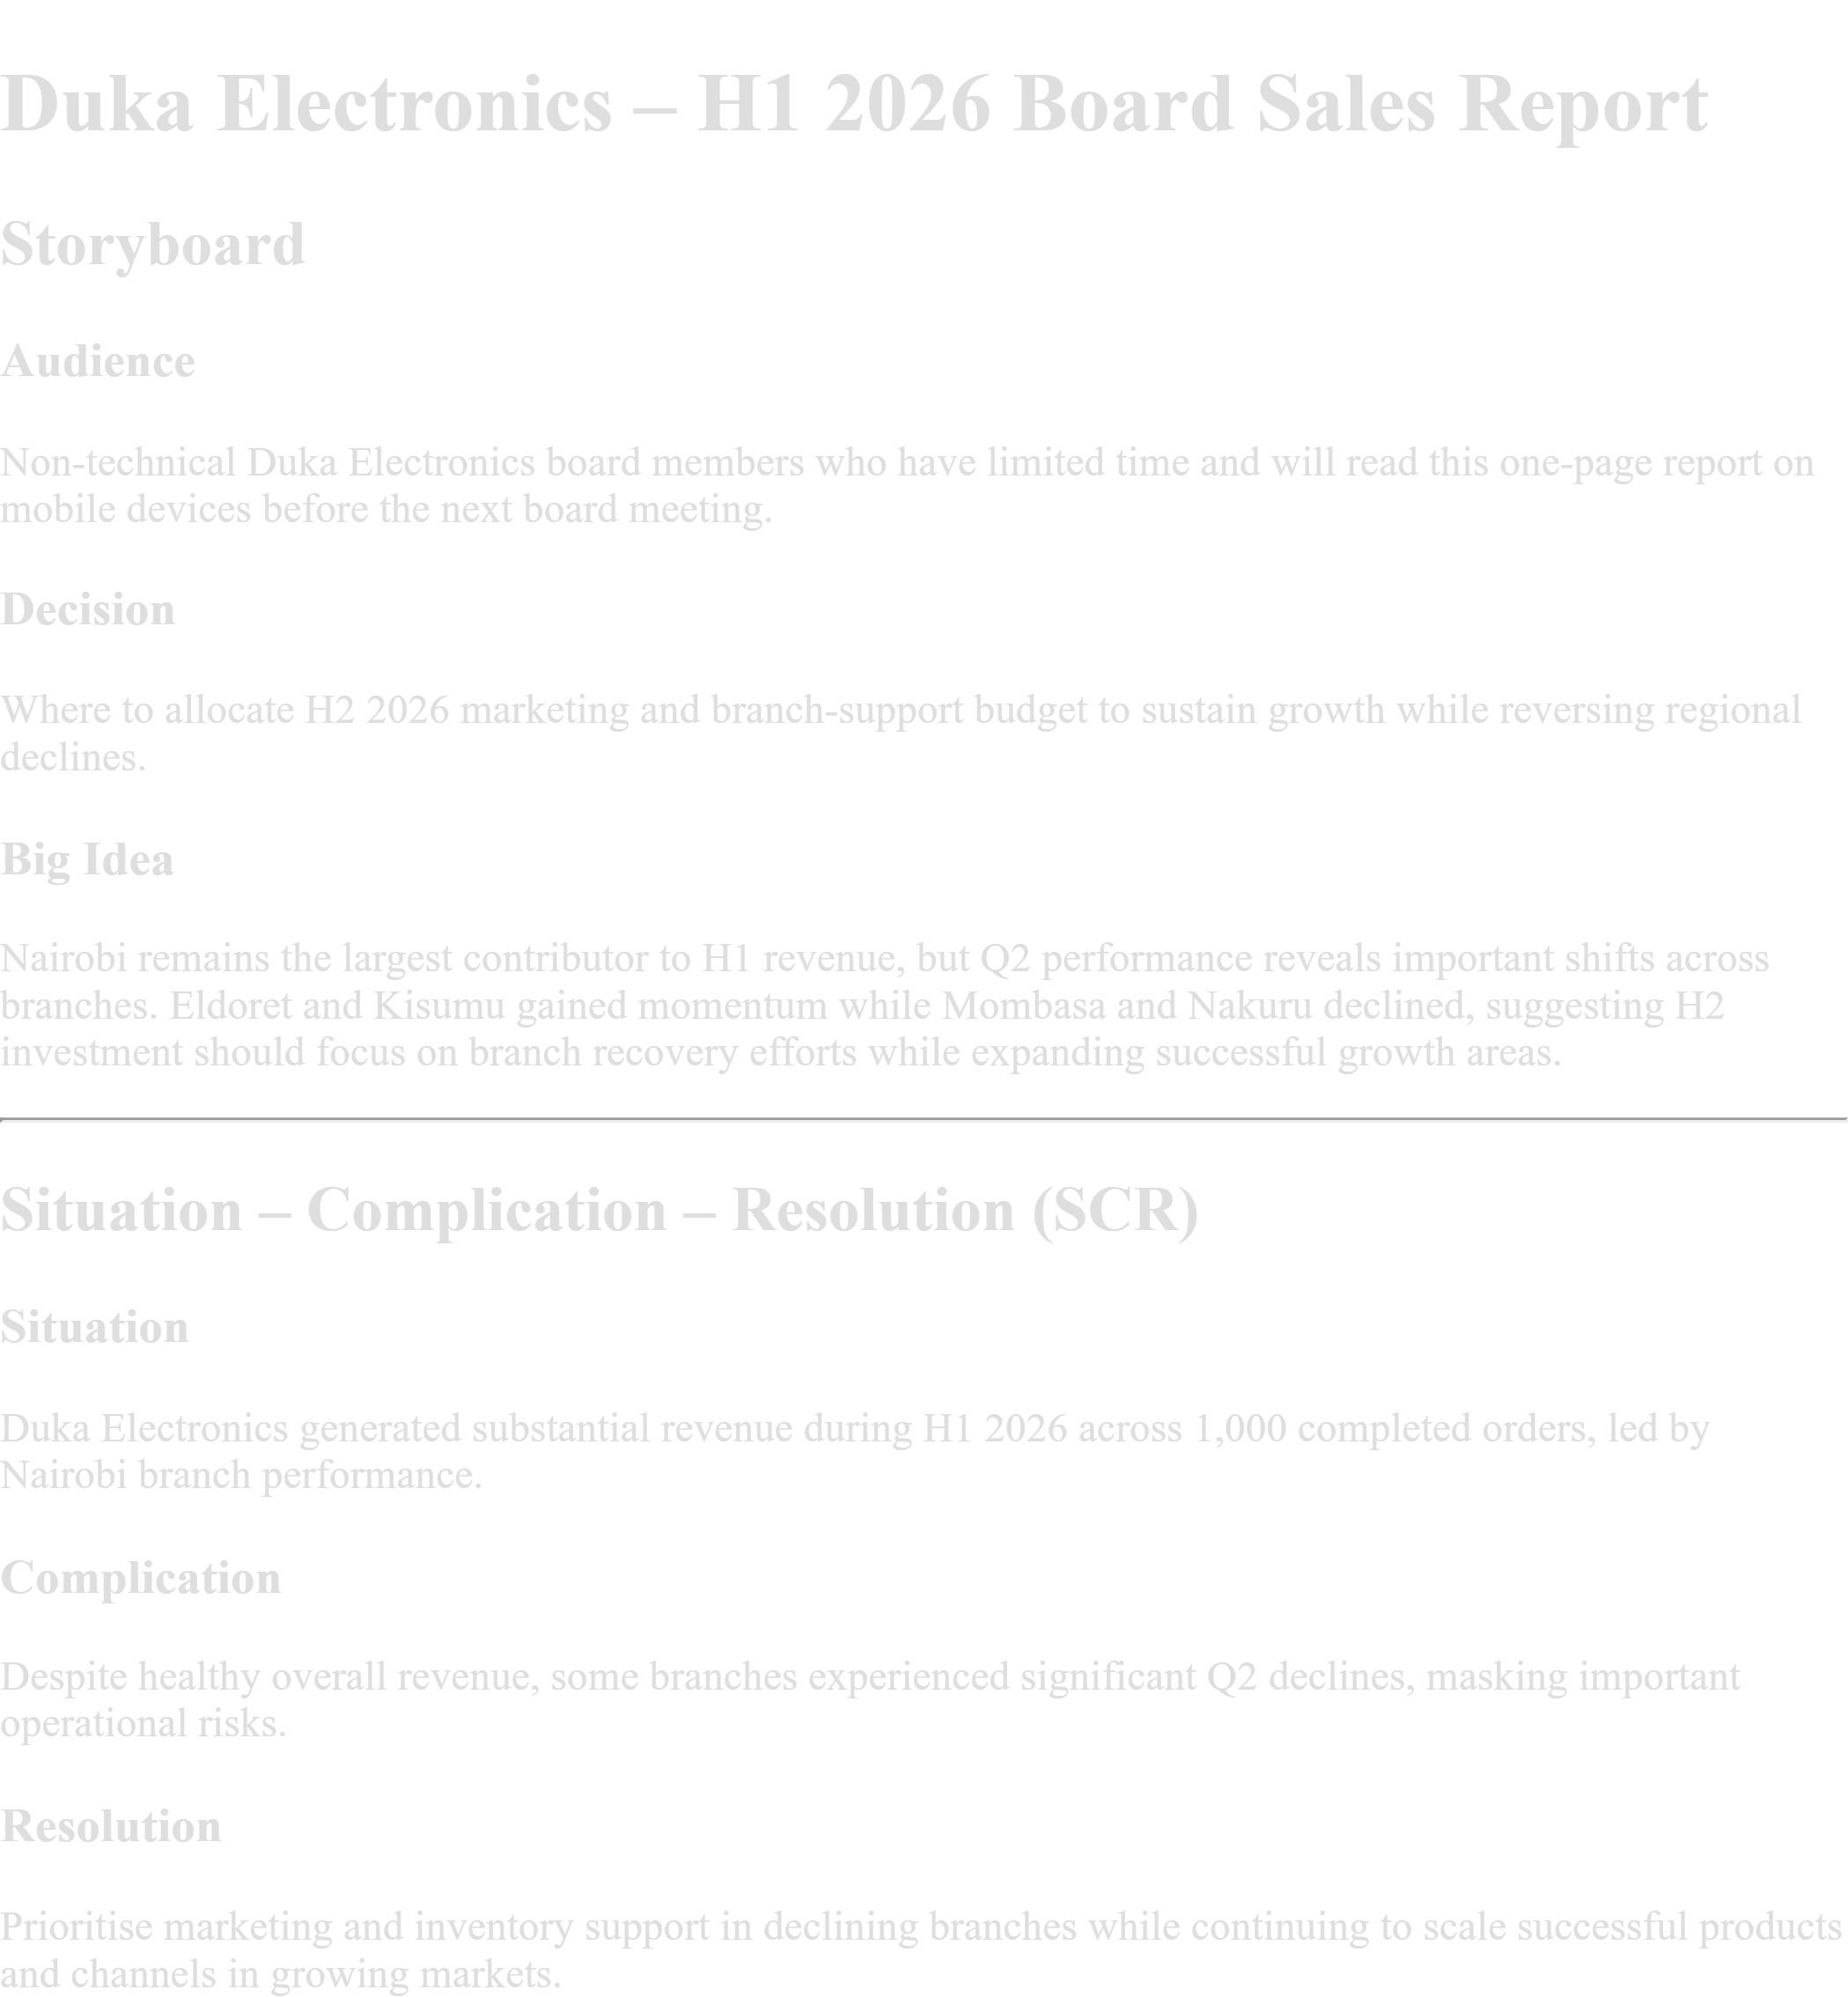

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
rng = np.random.default_rng(2026)

n = 1000

products = {
    "Phone": 15000,
    "Laptop": 65000,
    "Headphones": 2500,
    "Tablet": 28000,
    "Charger": 1200
}

sales = pd.DataFrame({
    "order_id": range(1001, 1001 + n),
    "order_date": (
        pd.to_datetime("2026-01-01")
        + pd.to_timedelta(
            rng.integers(0, 180, n),
            unit="D"
        )
    ),
    "branch": rng.choice(
        ["Nairobi", "Mombasa", "Kisumu", "Nakuru", "Eldoret"],
        n,
        p=[0.4, 0.2, 0.15, 0.15, 0.1]
    ),
    "product": rng.choice(
        list(products.keys()),
        n
    ),
    "quantity": rng.integers(1, 6, n),
    "channel": rng.choice(
        ["In-store", "Online", "Phone order"],
        n,
        p=[0.55, 0.35, 0.10]
    )
})

sales["unit_price"] = (
    sales["product"]
    .map(products)
)

sales.to_csv(
    "duka_sales.csv",
    index=False
)

print(
    "duka_sales.csv generated successfully."
)

print(
    "Rows:",
    len(sales)
)

duka_sales.csv generated successfully.
Rows: 1000


In [3]:
sales["revenue"] = (
    sales["quantity"]
    * sales["unit_price"]
)

sales["month"] = (
    sales["order_date"]
    .dt.to_period("M")
)

sales["quarter"] = np.where(
    sales["order_date"]
    .dt.month <= 3,
    "Q1",
    "Q2"
)

assert len(sales) == 1000
assert sales["revenue"].sum() > 0

print(
    f"Validation Passed: "
    f"{len(sales)} orders | "
    f"KES {sales['revenue'].sum():,.0f} revenue"
)

Validation Passed: 1000 orders | KES 71,792,500 revenue


In [4]:
export = sales.drop(
    columns=["month", "quarter"]
).copy()

export["order_date"] = (
    export["order_date"]
    .dt.strftime("%Y-%m-%d")
)

export.to_csv(
    "duka_dashboard_data.csv",
    index=False
)

print(
    "duka_dashboard_data.csv exported successfully."
)

display(export.head())

duka_dashboard_data.csv exported successfully.


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500


In [5]:
prod_rev = (
    sales
    .groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=True)
    / 1_000_000
)

display(
    prod_rev.to_frame(
        name="Revenue (KES Millions)"
    )
)

,Revenue (KES Millions)
product,
Charger,0.6420
Headphones,1.3875
Phone,8.8800
Tablet,19.3480
Laptop,41.5350


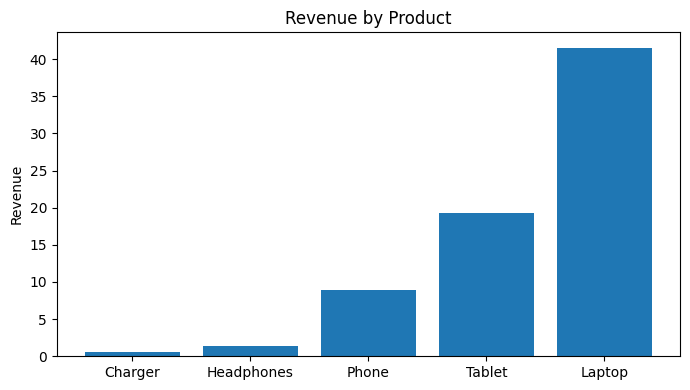

In [6]:
fig_before, ax_b = plt.subplots(
    figsize=(7, 4)
)

ax_b.bar(
    prod_rev.index,
    prod_rev.values
)

ax_b.set_title(
    "Revenue by Product"
)

ax_b.set_ylabel(
    "Revenue"
)

fig_before.tight_layout()

fig_before.savefig(
    "figures/before.png",
    dpi=150
)

plt.show()

In [7]:
top_prod = prod_rev.idxmax()

top_share = (
    prod_rev.max()
    / prod_rev.sum()
) * 100

print(
    f"Top Product: {top_prod}"
)

print(
    f"Revenue Share: {top_share:.1f}%"
)

Top Product: Laptop
Revenue Share: 57.9%


In [8]:
colors = [
    "#8E0000"
    if p == top_prod
    else "#B0B0B0"
    for p in prod_rev.index
]

colors

['#B0B0B0', '#B0B0B0', '#B0B0B0', '#B0B0B0', '#8E0000']

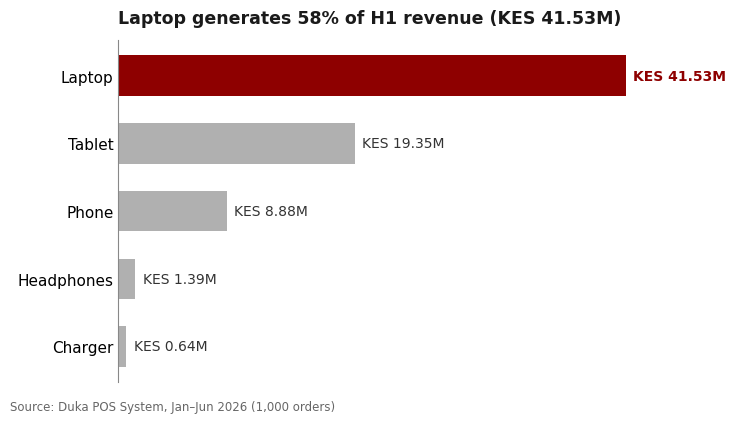

In [9]:
fig_after, ax_a = plt.subplots(
    figsize=(7.5, 4.2)
)

bars = ax_a.barh(
    prod_rev.index,
    prod_rev.values,
    color=colors,
    height=0.6
)

ax_a.spines[
    ["top", "right", "bottom"]
].set_visible(False)

ax_a.spines["left"].set_color(
    "#888888"
)

ax_a.xaxis.set_visible(False)

ax_a.tick_params(
    axis="y",
    length=0,
    labelsize=11
)

for bar, val in zip(
    bars,
    prod_rev.values
):

    ax_a.text(
        val + 0.6,
        bar.get_y()
        + bar.get_height()/2,
        f"KES {val:.2f}M",
        va="center",
        fontsize=10,
        fontweight=(
            "bold"
            if val == prod_rev.max()
            else "normal"
        ),
        color=(
            "#8E0000"
            if val == prod_rev.max()
            else "#333333"
        )
    )

ax_a.set_xlim(
    0,
    prod_rev.max() * 1.22
)

ax_a.set_title(
    f"{top_prod} generates "
    f"{top_share:.0f}% of H1 revenue "
    f"(KES {prod_rev.max():.2f}M)",
    loc="left",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
    color="#1A1A1A"
)

fig_after.text(
    0.01,
    0.01,
    "Source: Duka POS System, Jan–Jun 2026 (1,000 orders)",
    fontsize=8.5,
    color="#666666"
)

fig_after.tight_layout(
    rect=[0, 0.04, 1, 1]
)

fig_after.savefig(
    "figures/after.png",
    dpi=150
)

plt.show()

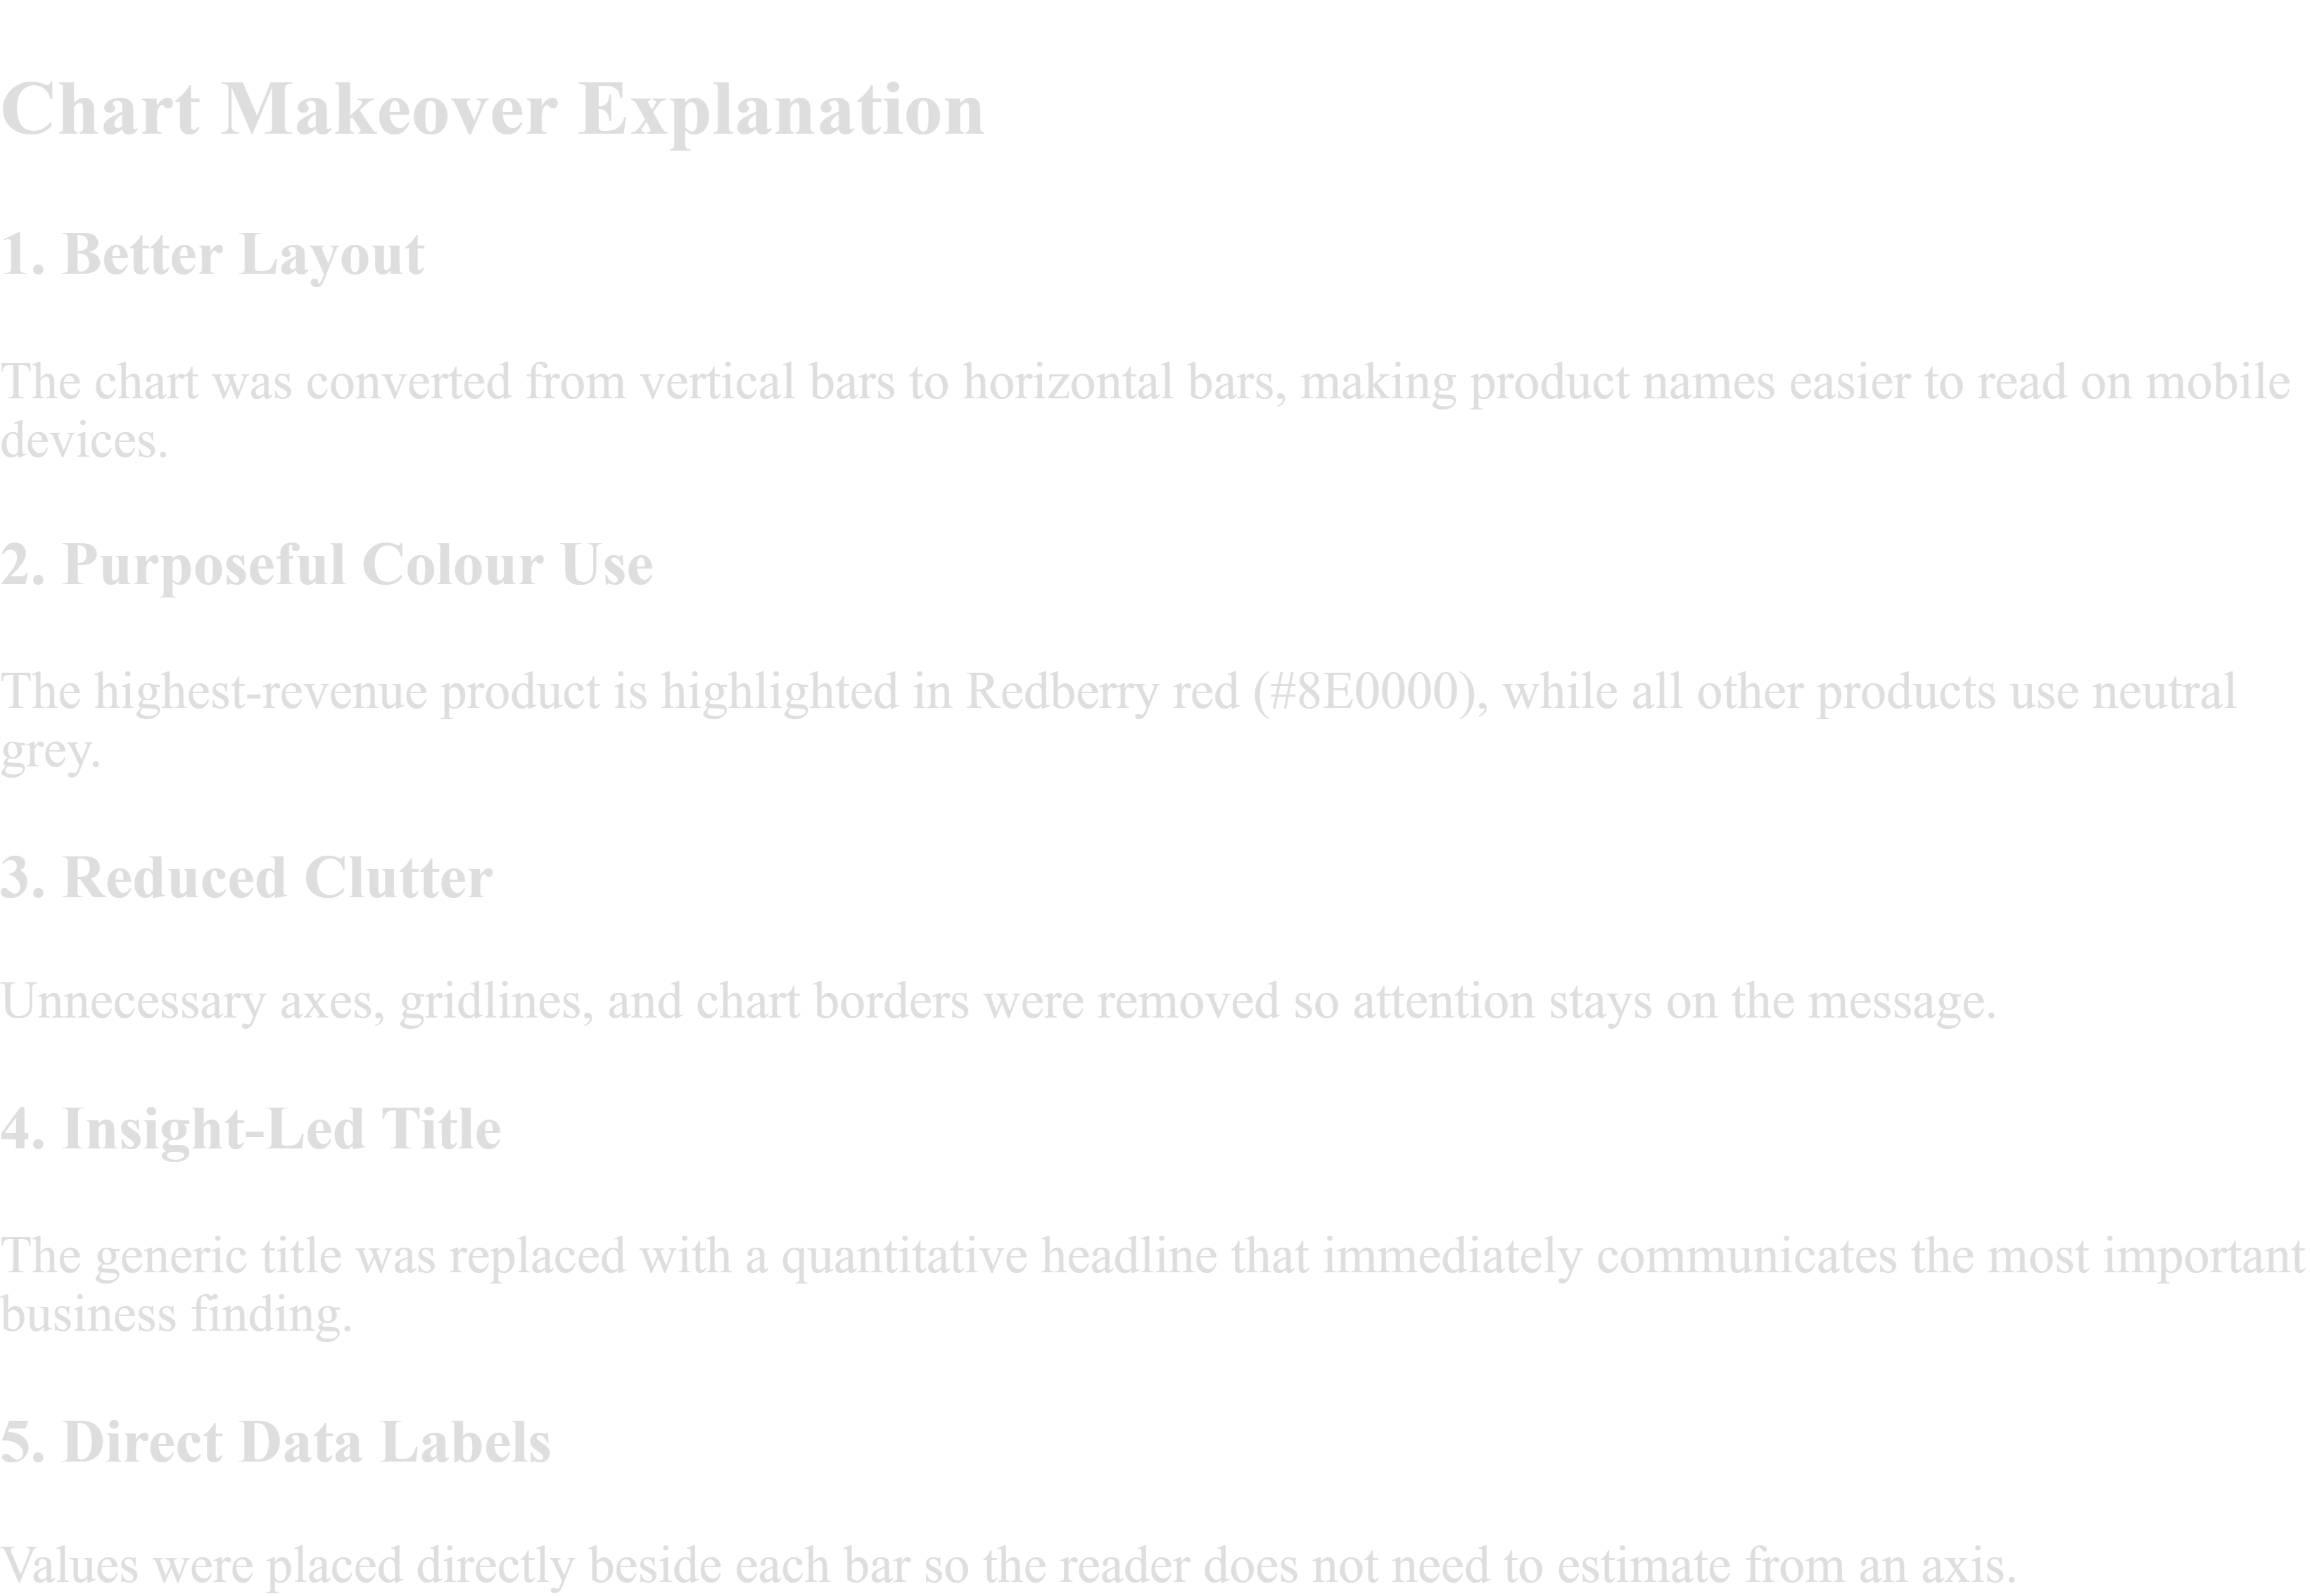

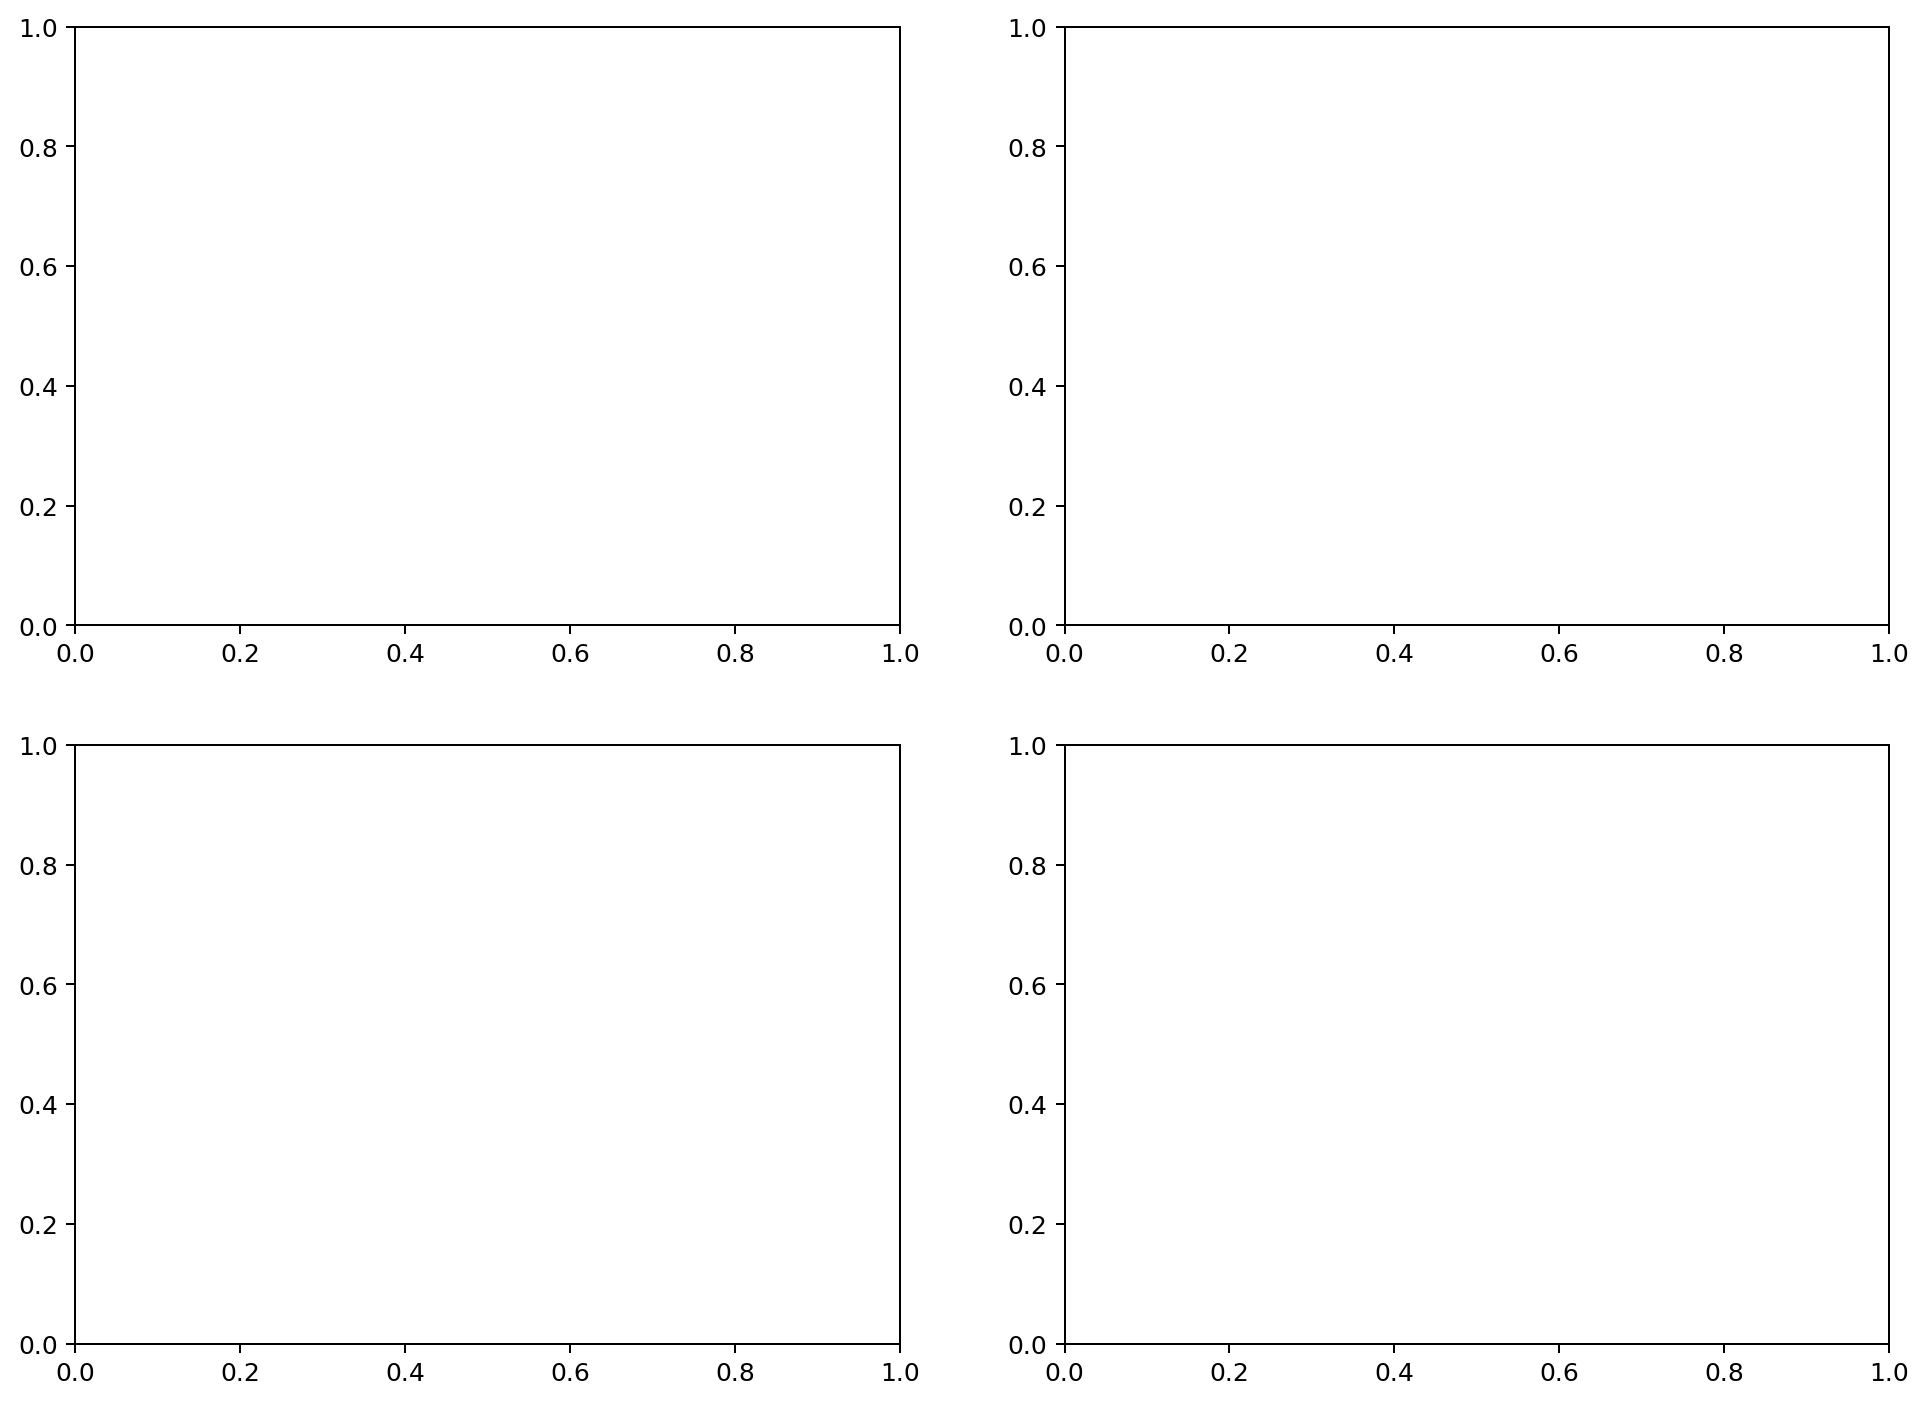

In [10]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9.5),
    dpi=180
)

fig.patch.set_facecolor("white")

In [11]:
fig.suptitle(
    "Nairobi remains the largest revenue contributor while Mombasa and Nakuru declined in Q2",
    fontsize=14,
    fontweight="bold",
    x=0.04,
    y=0.97,
    ha="left",
    color="#1A1A1A"
)

fig.text(
    0.04,
    0.935,
    f"Duka Electronics H1 2026 Board Review | "
    f"Total Revenue: KES {sales['revenue'].sum()/1e6:.2f}M | "
    f"{len(sales):,} Orders",
    fontsize=10.5,
    color="#555555"
)

Text(0.04, 0.935, 'Duka Electronics H1 2026 Board Review | Total Revenue: KES 71.79M | 1,000 Orders')

In [12]:
ax1 = axes[0, 0]

branch_rev = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values()
    / 1_000_000
)

nairobi_share = (
    branch_rev["Nairobi"]
    / branch_rev.sum()
) * 100

colors_branch = [
    "#8E0000"
    if x == "Nairobi"
    else "#B8B8B8"
    for x in branch_rev.index
]

bars1 = ax1.barh(
    branch_rev.index,
    branch_rev.values,
    color=colors_branch,
    height=0.58
)

ax1.spines[
    ["top", "right", "bottom"]
].set_visible(False)

ax1.xaxis.set_visible(False)

ax1.tick_params(
    axis="y",
    length=0
)

for bar, val in zip(
    bars1,
    branch_rev.values
):
    ax1.text(
        val + 0.3,
        bar.get_y() + bar.get_height()/2,
        f"{val:.2f}M",
        va="center",
        fontsize=9
    )

ax1.set_title(
    f"1. Nairobi contributes {nairobi_share:.0f}% of H1 revenue",
    loc="left",
    fontsize=11,
    fontweight="bold"
)

Text(0.0, 1.0, '1. Nairobi contributes 36% of H1 revenue')

In [13]:
ax2 = axes[0, 1]

q_piv = (
    sales.pivot_table(
        index="branch",
        columns="quarter",
        values="revenue",
        aggfunc="sum"
    ) / 1_000_000
)

q_piv["pct_chg"] = (
    (q_piv["Q2"] - q_piv["Q1"])
    / q_piv["Q1"]
) * 100

q_piv = q_piv.sort_values(
    "pct_chg"
)

best_branch = q_piv["pct_chg"].idxmax()
best_growth = q_piv["pct_chg"].max()

worst_branch = q_piv["pct_chg"].idxmin()
worst_decline = abs(
    q_piv["pct_chg"].min()
)

y_pos = np.arange(
    len(q_piv)
)

height = 0.35

ax2.barh(
    y_pos + height/2,
    q_piv["Q1"],
    height,
    color="#D0D0D0",
    label="Q1"
)

colors_q2 = [
    "#8E0000"
    if x < 0
    else "#0BA184"
    for x in q_piv["pct_chg"]
]

bars2 = ax2.barh(
    y_pos - height/2,
    q_piv["Q2"],
    height,
    color=colors_q2,
    label="Q2"
)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(
    q_piv.index
)

ax2.tick_params(
    axis="y",
    length=0
)

ax2.xaxis.set_visible(False)

ax2.spines[
    ["top", "right", "bottom"]
].set_visible(False)

ax2.legend(
    frameon=False
)

ax2.set_title(
    f"2. {best_branch} grew {best_growth:.0f}% while {worst_branch} fell {worst_decline:.0f}%",
    loc="left",
    fontsize=11,
    fontweight="bold"
)

Text(0.0, 1.0, '2. Eldoret grew 50% while Nakuru fell 27%')

In [14]:
ax3 = axes[1, 0]

monthly_rev = (
    sales.groupby("month")["revenue"]
    .sum()
    / 1_000_000
)

months_str = [
    str(x).replace("2026-", "")
    for x in monthly_rev.index.astype(str)
]

ax3.plot(
    months_str,
    monthly_rev.values,
    marker="o",
    linewidth=2.5,
    color="#333333"
)

ax3.spines[
    ["top", "right"]
].set_visible(False)

ax3.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

peak_idx = np.argmax(
    monthly_rev.values
)

low_idx = np.argmin(
    monthly_rev.values
)

ax3.plot(
    months_str[peak_idx],
    monthly_rev.values[peak_idx],
    marker="o",
    color="#0BA184",
    markersize=9
)

ax3.plot(
    months_str[low_idx],
    monthly_rev.values[low_idx],
    marker="o",
    color="#8E0000",
    markersize=9
)

for i, val in enumerate(
    monthly_rev.values
):
    ax3.text(
        i,
        val + 0.4,
        f"{val:.1f}M",
        ha="center",
        fontsize=8
    )

ax3.set_ylabel(
    "KES Millions"
)

ax3.set_title(
    f"3. Revenue peaked in {months_str[peak_idx]} at KES {monthly_rev.max():.2f}M",
    loc="left",
    fontsize=11,
    fontweight="bold"
)

Text(0.0, 1.0, '3. Revenue peaked in 04 at KES 13.52M')

In [15]:
ax4 = axes[1, 1]

chan_rev = (
    sales.groupby("channel")["revenue"]
    .sum()
    .sort_values()
    / 1_000_000
)

instore_share = (
    chan_rev["In-store"]
    / chan_rev.sum()
) * 100

colors_channel = [
    "#8E0000"
    if c == "In-store"
    else "#B8B8B8"
    for c in chan_rev.index
]

bars4 = ax4.barh(
    chan_rev.index,
    chan_rev.values,
    color=colors_channel,
    height=0.5
)

ax4.spines[
    ["top", "right", "bottom"]
].set_visible(False)

ax4.xaxis.set_visible(False)

ax4.tick_params(
    axis="y",
    length=0
)

for bar, val in zip(
    bars4,
    chan_rev.values
):
    share = (
        val / chan_rev.sum()
    ) * 100

    ax4.text(
        val + 0.4,
        bar.get_y() + bar.get_height()/2,
        f"{val:.2f}M ({share:.0f}%)",
        va="center",
        fontsize=9
    )

ax4.set_title(
    f"4. In-store contributes {instore_share:.0f}% of H1 revenue",
    loc="left",
    fontsize=11,
    fontweight="bold"
)

Text(0.0, 1.0, '4. In-store contributes 57% of H1 revenue')

In [16]:
fig.text(
    0.04,
    0.015,
    "Source: Duka Electronics POS System, Jan–Jun 2026. "
    "Red highlights indicate priority business areas.",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(
    rect=[0.03, 0.04, 0.98, 0.91]
)

plt.savefig(
    "reports/duka_board_report.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

reports/duka_board_report.png

In [17]:
branch_rev.to_csv(
    "reports/branch_revenue.csv"
)

q_piv.to_csv(
    "reports/q1_q2_branch_comparison.csv"
)

monthly_rev.to_csv(
    "reports/monthly_revenue.csv"
)

chan_rev.to_csv(
    "reports/channel_revenue.csv"
)

print("Supporting tables exported.")

Supporting tables exported.


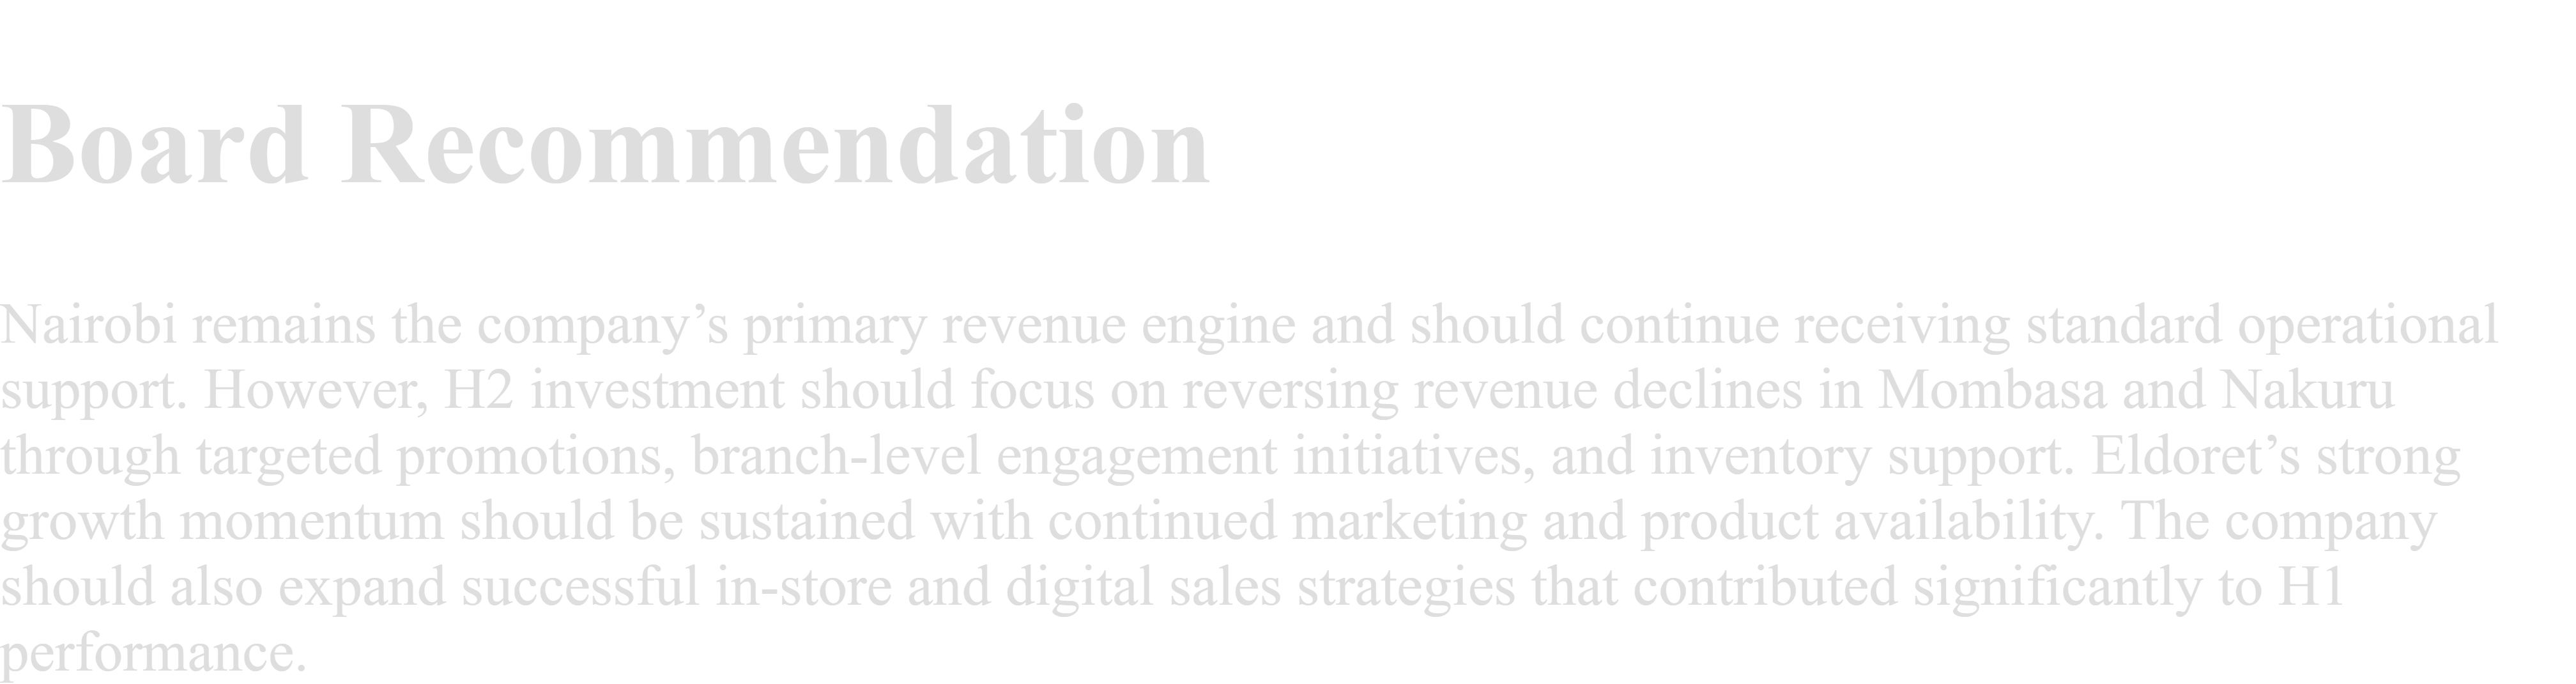